In [ ]:
!pip install -q xgboost shap scikit-learn pandas numpy matplotlib seaborn joblib

In [ ]:
# import library
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, RobustScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

from xgboost import XGBClassifier
import shap

In [ ]:
# Load Dataset
df = pd.read_csv("/content/bnpl_dataset_v2.csv")

print("Dataset berhasil dibaca.")
print("Ukuran dataset:", df.shape)

display(df.head())

Dataset berhasil dibaca.
Ukuran dataset: (50000, 13)


,Transaction_ID,Customer_Age,Gender,Annual_Income,Credit_Score,Purchase_Category,BNPL_Provider,Purchase_Amount,Device_Type,Connection_Type,Checkout_Time_Seconds,Browser,Repayment_Status
0,705eef54-52b2-4912-b562-d9f7b4184a6d,56,Male,32293,353,Beauty,Sezzle,249,Tablet,WiFi,82,Firefox,Paid On Time
1,7dbe58a0-0177-4572-8f3a-566d907e9c56,46,Male,72774,354,Groceries,Affirm,188,Mobile,WiFi,60,Firefox,Paid On Time
2,b77e4be3-bf88-4bb0-addb-45d84e6a3f65,32,Male,82207,630,Travel,Sezzle,1610,Desktop,WiFi,86,Chrome,Paid On Time
3,5c3c24a8-675e-46fd-8312-4ac37cbb97c5,60,Male,92498,470,Fashion,Sezzle,120,Mobile,4G/5G,169,Chrome,Paid On Time
4,4bb92076-f15e-4cfc-8aac-58395d69aedc,25,Male,32060,502,Travel,Klarna,1849,Mobile,4G/5G,38,Chrome,Defaulted


In [ ]:
# cek informasi dataset
missing_values = df.isnull().sum().sort_values(ascending=False)
missing_percent = (missing_values / len(df)) * 100

missing_table = pd.DataFrame({
    "missing_count": missing_values,
    "missing_percent": missing_percent
})

display(missing_table[missing_table["missing_count"] >= 0])

,missing_count,missing_percent
Transaction_ID,0,0.0
Customer_Age,0,0.0
Gender,0,0.0
Annual_Income,0,0.0
Credit_Score,0,0.0
Purchase_Category,0,0.0
BNPL_Provider,0,0.0
Purchase_Amount,0,0.0
Device_Type,0,0.0
Connection_Type,0,0.0


In [ ]:
# merapikan nama kolom
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .str.replace("-", "_")
    .str.replace("/", "_")
)

print(df.columns.tolist())

['transaction_id', 'customer_age', 'gender', 'annual_income', 'credit_score', 'purchase_category', 'bnpl_provider', 'purchase_amount', 'device_type', 'connection_type', 'checkout_time_seconds', 'browser', 'repayment_status']


In [ ]:
# cek target asli
target_col = "repayment_status"

print("Distribusi target asli:")
print(df[target_col].value_counts())

Distribusi target asli:
repayment_status
Paid On Time    38399
Late Payment     7364
Defaulted        4237
Name: count, dtype: int64


In [ ]:
# data cleaning
df_model = df.copy()

print("Jumlah data sebelum hapus duplikat:", df_model.shape[0])
df_model = df_model.drop_duplicates()
print("Jumlah data setelah hapus duplikat:", df_model.shape[0])

# pastikan kolom numerik benar
numeric_candidate_cols = [
    "customer_age",
    "annual_income",
    "credit_score",
    "purchase_amount",
    "checkout_time_seconds"
]

for col in numeric_candidate_cols:
    if col in df_model.columns:
        df_model[col] = pd.to_numeric(df_model[col], errors="coerce")

Jumlah data sebelum hapus duplikat: 50000
Jumlah data setelah hapus duplikat: 50000


In [ ]:
# target binary
def map_repayment_status(value):
    value = str(value).lower().strip()

    bad_words = [
        "late",
        "delayed",
        "delay",
        "overdue",
        "default",
        "failed",
        "missed",
        "unpaid",
        "not paid"
    ]

    good_words = [
        "paid on time",
        "on time",
        "paid",
        "completed",
        "success",
        "successful"
    ]

    if any(word in value for word in bad_words):
        return 1
    elif any(word in value for word in good_words):
        return 0
    else:
        return np.nan

df_model["default_binary"] = df_model[target_col].apply(map_repayment_status)

print("Cek hasil mapping target:")
print(df_model[[target_col, "default_binary"]].drop_duplicates())

# hapus data jika ada label yang tidak terbaca
df_model = df_model.dropna(subset=["default_binary"])
df_model["default_binary"] = df_model["default_binary"].astype(int)

print("\nDistribusi target binary:")
print(df_model["default_binary"].value_counts())
print(df_model["default_binary"].value_counts(normalize=True) * 100)

Cek hasil mapping target:
  repayment_status  default_binary
0     Paid On Time               0
4        Defaulted               1
8     Late Payment               1

Distribusi target binary:
default_binary
0    38399
1    11601
Name: count, dtype: int64
default_binary
0    76.798
1    23.202
Name: proportion, dtype: float64


In [ ]:
# feature engineering
# Rasio pembelian terhadap pendapatan
df_model["purchase_to_income_ratio"] = (
    df_model["purchase_amount"] / (df_model["annual_income"] + 1)
)

# Rasio pendapatan terhadap pembelian
df_model["income_to_purchase_ratio"] = (
    df_model["annual_income"] / (df_model["purchase_amount"] + 1)
)

# Log transform agar distribusi lebih stabil
df_model["log_annual_income"] = np.log1p(df_model["annual_income"])
df_model["log_purchase_amount"] = np.log1p(df_model["purchase_amount"])
df_model["log_checkout_time"] = np.log1p(df_model["checkout_time_seconds"])

# Flag risiko sederhana
df_model["low_credit_score_flag"] = (df_model["credit_score"] < 550).astype(int)
df_model["very_low_credit_score_flag"] = (df_model["credit_score"] < 450).astype(int)

df_model["high_purchase_flag"] = (
    df_model["purchase_amount"] > df_model["purchase_amount"].quantile(0.75)
).astype(int)

df_model["low_income_flag"] = (
    df_model["annual_income"] < df_model["annual_income"].quantile(0.25)
).astype(int)

df_model["long_checkout_flag"] = (
    df_model["checkout_time_seconds"] > df_model["checkout_time_seconds"].quantile(0.75)
).astype(int)

# Jarak dari skor kredit ideal
df_model["credit_risk_distance"] = 850 - df_model["credit_score"]

# Kombinasi risiko sederhana
df_model["risk_pressure_score"] = (
    df_model["purchase_to_income_ratio"] * 1000
    + df_model["low_credit_score_flag"] * 2
    + df_model["high_purchase_flag"]
)

# Kategori umur
df_model["age_group"] = pd.cut(
    df_model["customer_age"],
    bins=[0, 25, 35, 45, 55, 100],
    labels=["<=25", "26-35", "36-45", "46-55", ">55"]
).astype(str)

# Kategori credit score
df_model["credit_score_group"] = pd.cut(
    df_model["credit_score"],
    bins=[0, 450, 550, 650, 750, 900],
    labels=["Very Low", "Low", "Medium", "Good", "Excellent"]
).astype(str)

# Income quartile
df_model["income_quartile"] = pd.qcut(
    df_model["annual_income"],
    q=4,
    labels=False,
    duplicates="drop"
).astype(str)

# Kombinasi kategori dan provider
df_model["category_provider"] = (
    df_model["purchase_category"].astype(str)
    + "_"
    + df_model["bnpl_provider"].astype(str)
)

display(df_model.head())

,transaction_id,customer_age,gender,annual_income,credit_score,purchase_category,bnpl_provider,purchase_amount,device_type,connection_type,...,very_low_credit_score_flag,high_purchase_flag,low_income_flag,long_checkout_flag,credit_risk_distance,risk_pressure_score,age_group,credit_score_group,income_quartile,category_provider
0,705eef54-52b2-4912-b562-d9f7b4184a6d,56,Male,32293,353,Beauty,Sezzle,249,Tablet,WiFi,...,1,0,1,0,497,9.710411,>55,Very Low,0,Beauty_Sezzle
1,7dbe58a0-0177-4572-8f3a-566d907e9c56,46,Male,72774,354,Groceries,Affirm,188,Mobile,WiFi,...,1,0,0,0,496,4.583305,46-55,Very Low,2,Groceries_Affirm
2,b77e4be3-bf88-4bb0-addb-45d84e6a3f65,32,Male,82207,630,Travel,Sezzle,1610,Desktop,WiFi,...,0,1,0,0,220,20.584469,26-35,Medium,2,Travel_Sezzle
3,5c3c24a8-675e-46fd-8312-4ac37cbb97c5,60,Male,92498,470,Fashion,Sezzle,120,Mobile,4G/5G,...,0,0,0,1,380,3.297311,>55,Low,2,Fashion_Sezzle
4,4bb92076-f15e-4cfc-8aac-58395d69aedc,25,Male,32060,502,Travel,Klarna,1849,Mobile,4G/5G,...,0,1,1,0,348,60.671314,<=25,Low,0,Travel_Klarna


In [ ]:
# memisahkan fitur dan target
id_cols = []

# hanya drop ID transaksi, bukan customer_age dan bukan bnpl_provider
if "transaction_id" in df_model.columns:
    id_cols.append("transaction_id")

drop_cols = id_cols + [target_col, "default_binary"]

X_base = df_model.drop(columns=drop_cols, errors="ignore")
y = df_model["default_binary"]

print("Kolom yang dihapus:", drop_cols)
print("Shape X:", X_base.shape)
print("Shape y:", y.shape)

display(X_base.head())

Kolom yang dihapus: ['transaction_id', 'repayment_status', 'default_binary']
Shape X: (50000, 27)
Shape y: (50000,)


,customer_age,gender,annual_income,credit_score,purchase_category,bnpl_provider,purchase_amount,device_type,connection_type,checkout_time_seconds,...,very_low_credit_score_flag,high_purchase_flag,low_income_flag,long_checkout_flag,credit_risk_distance,risk_pressure_score,age_group,credit_score_group,income_quartile,category_provider
0,56,Male,32293,353,Beauty,Sezzle,249,Tablet,WiFi,82,...,1,0,1,0,497,9.710411,>55,Very Low,0,Beauty_Sezzle
1,46,Male,72774,354,Groceries,Affirm,188,Mobile,WiFi,60,...,1,0,0,0,496,4.583305,46-55,Very Low,2,Groceries_Affirm
2,32,Male,82207,630,Travel,Sezzle,1610,Desktop,WiFi,86,...,0,1,0,0,220,20.584469,26-35,Medium,2,Travel_Sezzle
3,60,Male,92498,470,Fashion,Sezzle,120,Mobile,4G/5G,169,...,0,0,0,1,380,3.297311,>55,Low,2,Fashion_Sezzle
4,25,Male,32060,502,Travel,Klarna,1849,Mobile,4G/5G,38,...,0,1,1,0,348,60.671314,<=25,Low,0,Travel_Klarna


In [ ]:
# hapus fitur konstan
constant_cols = []

for col in X_base.columns:
    if X_base[col].nunique(dropna=True) <= 1:
        constant_cols.append(col)

print("Kolom konstan:", constant_cols)

X_base = X_base.drop(columns=constant_cols, errors="ignore")

print("Shape X setelah hapus kolom konstan:", X_base.shape)

Kolom konstan: []
Shape X setelah hapus kolom konstan: (50000, 27)


In [ ]:
# hapus kolom credit_score
df_model = df_model.drop(columns=["credit_score"], errors="ignore")

In [ ]:
# split data
X_train_base, X_test_base, y_train, y_test = train_test_split(
    X_base,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train_base.shape)
print("X_test:", X_test_base.shape)

print("\nDistribusi train:")
print(y_train.value_counts(normalize=True) * 100)

print("\nDistribusi test:")
print(y_test.value_counts(normalize=True) * 100)

X_train: (40000, 27)
X_test: (10000, 27)

Distribusi train:
default_binary
0    76.7975
1    23.2025
Name: proportion, dtype: float64

Distribusi test:
default_binary
0    76.8
1    23.2
Name: proportion, dtype: float64


In [ ]:
# onehotencoder
def make_ohe():
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)

In [ ]:
# clustering
numeric_features_cluster = X_train_base.select_dtypes(include=["int64", "float64", "int32", "float32"]).columns.tolist()
categorical_features_cluster = X_train_base.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

cluster_numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cluster_categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", make_ohe())
])

cluster_preprocessor = ColumnTransformer(
    transformers=[
        ("num", cluster_numeric_transformer, numeric_features_cluster),
        ("cat", cluster_categorical_transformer, categorical_features_cluster)
    ]
)

X_train_cluster_processed = cluster_preprocessor.fit_transform(X_train_base)
X_test_cluster_processed = cluster_preprocessor.transform(X_test_base)

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

train_clusters = kmeans.fit_predict(X_train_cluster_processed)
test_clusters = kmeans.predict(X_test_cluster_processed)

# mapping cluster berdasarkan rata-rata risiko pada data train
cluster_risk = pd.DataFrame({
    "cluster": train_clusters,
    "default_binary": y_train.values
}).groupby("cluster")["default_binary"].mean().sort_values()

cluster_order = cluster_risk.index.tolist()

persona_mapping = {
    cluster_order[0]: "Responsible User",
    cluster_order[1]: "Promo Hunter",
    cluster_order[2]: "Frequent Borrower",
    cluster_order[3]: "High Risk Borrower"
}

print("Rata-rata risiko per cluster:")
display(cluster_risk)

print("Mapping persona:")
print(persona_mapping)

X_train = X_train_base.copy()
X_test = X_test_base.copy()

X_train["persona_cluster"] = pd.Series(train_clusters, index=X_train.index).map(persona_mapping)
X_test["persona_cluster"] = pd.Series(test_clusters, index=X_test.index).map(persona_mapping)

display(X_train.head())

Rata-rata risiko per cluster:


,default_binary
cluster,
1,0.122025
2,0.232016
3,0.262164
0,0.335882


Mapping persona:
{1: 'Responsible User', 2: 'Promo Hunter', 3: 'Frequent Borrower', 0: 'High Risk Borrower'}


,customer_age,gender,annual_income,credit_score,purchase_category,bnpl_provider,purchase_amount,device_type,connection_type,checkout_time_seconds,...,high_purchase_flag,low_income_flag,long_checkout_flag,credit_risk_distance,risk_pressure_score,age_group,credit_score_group,income_quartile,category_provider,persona_cluster
33608,34,Male,102262,651,Home & Furniture,Affirm,76,Mobile,4G/5G,154,...,0,0,1,199,0.743182,26-35,Good,3,Home & Furniture_Affirm,Responsible User
41828,44,Male,47009,582,Home & Furniture,Affirm,277,Mobile,WiFi,173,...,0,0,1,268,5.892363,36-45,Medium,1,Home & Furniture_Affirm,Responsible User
15748,47,Male,83392,300,Electronics,Afterpay,1820,Mobile,4G/5G,167,...,1,0,1,550,24.824374,46-55,Very Low,2,Electronics_Afterpay,Promo Hunter
28917,64,Male,22232,492,Beauty,Afterpay,265,Desktop,WiFi,35,...,0,1,0,358,13.919219,>55,Low,0,Beauty_Afterpay,Frequent Borrower
31579,19,Non-Binary,63922,488,Beauty,Sezzle,143,Desktop,WiFi,17,...,0,0,0,362,4.237066,<=25,Low,1,Beauty_Sezzle,High Risk Borrower


In [ ]:
# pre-processing XGBoost
numeric_features = X_train.select_dtypes(include=["int64", "float64", "int32", "float32"]).columns.tolist()
categorical_features = X_train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("Fitur numerik:", numeric_features)
print("Fitur kategorikal:", categorical_features)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", make_ohe())
])

model_preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

X_train_processed = model_preprocessor.fit_transform(X_train)
X_test_processed = model_preprocessor.transform(X_test)

print("X_train_processed:", X_train_processed.shape)
print("X_test_processed:", X_test_processed.shape)

Fitur numerik: ['customer_age', 'annual_income', 'credit_score', 'purchase_amount', 'checkout_time_seconds', 'purchase_to_income_ratio', 'income_to_purchase_ratio', 'log_annual_income', 'log_purchase_amount', 'log_checkout_time', 'low_credit_score_flag', 'very_low_credit_score_flag', 'high_purchase_flag', 'low_income_flag', 'long_checkout_flag', 'credit_risk_distance', 'risk_pressure_score']
Fitur kategorikal: ['gender', 'purchase_category', 'bnpl_provider', 'device_type', 'connection_type', 'browser', 'age_group', 'credit_score_group', 'income_quartile', 'category_provider', 'persona_cluster']
X_train_processed: (40000, 82)
X_test_processed: (10000, 82)


In [ ]:
# ambil nama fitur setelah encoding
feature_names_num = numeric_features

if len(categorical_features) > 0:
    encoder = model_preprocessor.named_transformers_["cat"].named_steps["encoder"]
    feature_names_cat = encoder.get_feature_names_out(categorical_features).tolist()
else:
    feature_names_cat = []

feature_names = feature_names_num + feature_names_cat

print("Jumlah fitur akhir:", len(feature_names))
print(feature_names[:30])

Jumlah fitur akhir: 82
['customer_age', 'annual_income', 'credit_score', 'purchase_amount', 'checkout_time_seconds', 'purchase_to_income_ratio', 'income_to_purchase_ratio', 'log_annual_income', 'log_purchase_amount', 'log_checkout_time', 'low_credit_score_flag', 'very_low_credit_score_flag', 'high_purchase_flag', 'low_income_flag', 'long_checkout_flag', 'credit_risk_distance', 'risk_pressure_score', 'gender_Female', 'gender_Male', 'gender_Non-Binary', 'purchase_category_Beauty', 'purchase_category_Electronics', 'purchase_category_Fashion', 'purchase_category_Groceries', 'purchase_category_Home & Furniture', 'purchase_category_Travel', 'bnpl_provider_Affirm', 'bnpl_provider_Afterpay', 'bnpl_provider_Klarna', 'bnpl_provider_Sezzle']


In [ ]:
# train XGBoost
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()

scale_pos_weight = neg_count / pos_count

print("Jumlah kelas 0:", neg_count)
print("Jumlah kelas 1:", pos_count)
print("scale_pos_weight:", scale_pos_weight)

xgb_model = XGBClassifier(
    n_estimators=700,
    max_depth=3,
    learning_rate=0.03,
    min_child_weight=3,
    gamma=0.1,
    subsample=0.85,
    colsample_bytree=0.85,
    reg_alpha=0.2,
    reg_lambda=2.0,
    scale_pos_weight=scale_pos_weight,
    eval_metric="aucpr",
    tree_method="hist",
    random_state=42
)

xgb_model.fit(X_train_processed, y_train)

Jumlah kelas 0: 30719
Jumlah kelas 1: 9281
scale_pos_weight: 3.3098804008188774


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.85, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='aucpr', feature_types=None,
              feature_weights=None, gamma=0.1, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.03, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=3,
              max_leaves=None, min_child_weight=3, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=700,
              n_jobs=None, num_parallel_tree=None, ...)

Evaluasi Threshold 0.5
Accuracy: 0.6213
Balanced Accuracy: 0.6770406788793103
F1 Score: 0.4890028336256915
ROC AUC: 0.710789865077227
PR AUC: 0.44578140757750806

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.57      0.70      7680
           1       0.36      0.78      0.49      2320

    accuracy                           0.62     10000
   macro avg       0.63      0.68      0.59     10000
weighted avg       0.77      0.62      0.65     10000



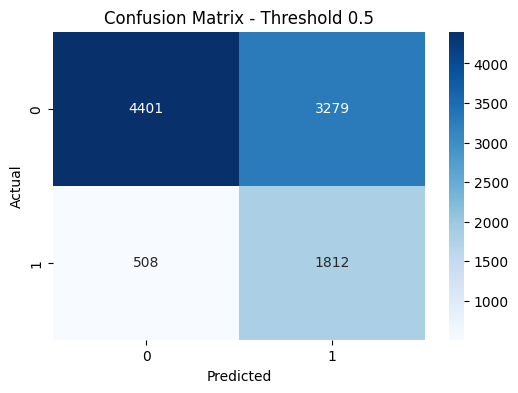

In [ ]:
# evaluasi
y_proba = xgb_model.predict_proba(X_test_processed)[:, 1]
y_pred_default = (y_proba >= 0.5).astype(int)

print("Evaluasi Threshold 0.5")
print("Accuracy:", accuracy_score(y_test, y_pred_default))
print("Balanced Accuracy:", balanced_accuracy_score(y_test, y_pred_default))
print("F1 Score:", f1_score(y_test, y_pred_default))
print("ROC AUC:", roc_auc_score(y_test, y_proba))
print("PR AUC:", average_precision_score(y_test, y_proba))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_default, zero_division=0))

cm = confusion_matrix(y_test, y_pred_default)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Threshold 0.5")
plt.show()

In [ ]:
# threshold tuning
threshold_results = []

for threshold in np.arange(0.10, 0.90, 0.01):
    y_pred_temp = (y_proba >= threshold).astype(int)

    precision = precision_score(y_test, y_pred_temp, zero_division=0)
    recall = recall_score(y_test, y_pred_temp, zero_division=0)
    f1 = f1_score(y_test, y_pred_temp, zero_division=0)
    f2 = fbeta_score(y_test, y_pred_temp, beta=2, zero_division=0)
    balanced_acc = balanced_accuracy_score(y_test, y_pred_temp)

    threshold_results.append({
        "threshold": round(threshold, 2),
        "precision": precision,
        "recall": recall,
        "f1_score": f1,
        "f2_score": f2,
        "balanced_accuracy": balanced_acc
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.sort_values("f2_score", ascending=False).head(15))

,threshold,precision,recall,f1_score,f2_score,balanced_accuracy
30,0.40,0.352963,0.803448,0.490462,0.640066,0.679263
28,0.38,0.351326,0.805172,0.489197,0.639858,0.678042
29,0.39,0.352219,0.803879,0.489823,0.639794,0.678632
27,0.37,0.349458,0.806466,0.487621,0.639265,0.676475
26,0.36,0.348133,0.807759,0.486564,0.639023,0.675429
31,0.41,0.353120,0.800000,0.489968,0.638415,0.678646
24,0.34,0.342971,0.812931,0.482415,0.638068,0.671244
25,0.35,0.345157,0.809483,0.483958,0.637864,0.672775
32,0.42,0.353526,0.797414,0.489872,0.637360,0.678460
23,0.33,0.338770,0.814655,0.478542,0.635978,0.667158


Best threshold: 0.4


,30
threshold,0.400000
precision,0.352963
recall,0.803448
f1_score,0.490462
f2_score,0.640066
balanced_accuracy,0.679263


Evaluasi Threshold Terbaik
Accuracy: 0.6127
Balanced Accuracy: 0.6792632004310345
F1 Score: 0.4904617813445599
ROC AUC: 0.710789865077227
PR AUC: 0.44578140757750806

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.56      0.69      7680
           1       0.35      0.80      0.49      2320

    accuracy                           0.61     10000
   macro avg       0.63      0.68      0.59     10000
weighted avg       0.78      0.61      0.64     10000



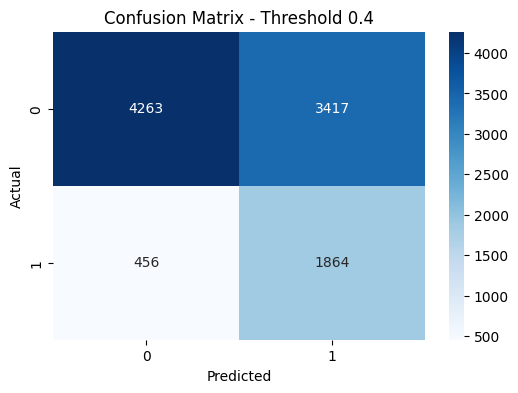

In [ ]:
# pakai threshold terbaik
best_row = threshold_df.sort_values("f2_score", ascending=False).iloc[0]
best_threshold = best_row["threshold"]

print("Best threshold:", best_threshold)
display(best_row)

y_pred_best = (y_proba >= best_threshold).astype(int)

print("Evaluasi Threshold Terbaik")
print("Accuracy:", accuracy_score(y_test, y_pred_best))
print("Balanced Accuracy:", balanced_accuracy_score(y_test, y_pred_best))
print("F1 Score:", f1_score(y_test, y_pred_best))
print("ROC AUC:", roc_auc_score(y_test, y_proba))
print("PR AUC:", average_precision_score(y_test, y_proba))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_best, zero_division=0))

cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix - Threshold {best_threshold}")
plt.show()

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=10,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),
    "XGBoost": XGBClassifier(
        n_estimators=700,
        max_depth=3,
        learning_rate=0.03,
        min_child_weight=3,
        gamma=0.1,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_alpha=0.2,
        reg_lambda=2.0,
        scale_pos_weight=scale_pos_weight,
        eval_metric="aucpr",
        tree_method="hist",
        random_state=42
    )
}

comparison_results = []

for model_name, model in models.items():
    model.fit(X_train_processed, y_train)

    y_proba_model = model.predict_proba(X_test_processed)[:, 1]

    # pakai threshold 0.4 agar fair dengan model sebelumnya
    y_pred_model = (y_proba_model >= 0.4).astype(int)

    comparison_results.append({
        "model": model_name,
        "accuracy": accuracy_score(y_test, y_pred_model),
        "precision_1": precision_score(y_test, y_pred_model, zero_division=0),
        "recall_1": recall_score(y_test, y_pred_model, zero_division=0),
        "f1_1": f1_score(y_test, y_pred_model, zero_division=0),
        "roc_auc": roc_auc_score(y_test, y_proba_model),
        "pr_auc": average_precision_score(y_test, y_proba_model)
    })

comparison_df = pd.DataFrame(comparison_results)
display(comparison_df.sort_values("f1_1", ascending=False))

,model,accuracy,precision_1,recall_1,f1_1,roc_auc,pr_auc
2,XGBoost,0.6127,0.352963,0.803448,0.490462,0.710790,0.445781
1,Random Forest,0.6181,0.354211,0.784914,0.488138,0.709776,0.437682
0,Logistic Regression,0.5880,0.334983,0.787500,0.470028,0.703210,0.425972


,feature,importance
15,credit_risk_distance,0.159162
34,connection_type_VPN,0.094462
33,connection_type_4G/5G,0.082786
2,credit_score,0.070138
78,persona_cluster_Frequent Borrower,0.018813
31,device_type_Mobile,0.017229
35,connection_type_WiFi,0.017203
50,income_quartile_0,0.016848
81,persona_cluster_Responsible User,0.013609
27,bnpl_provider_Afterpay,0.012514


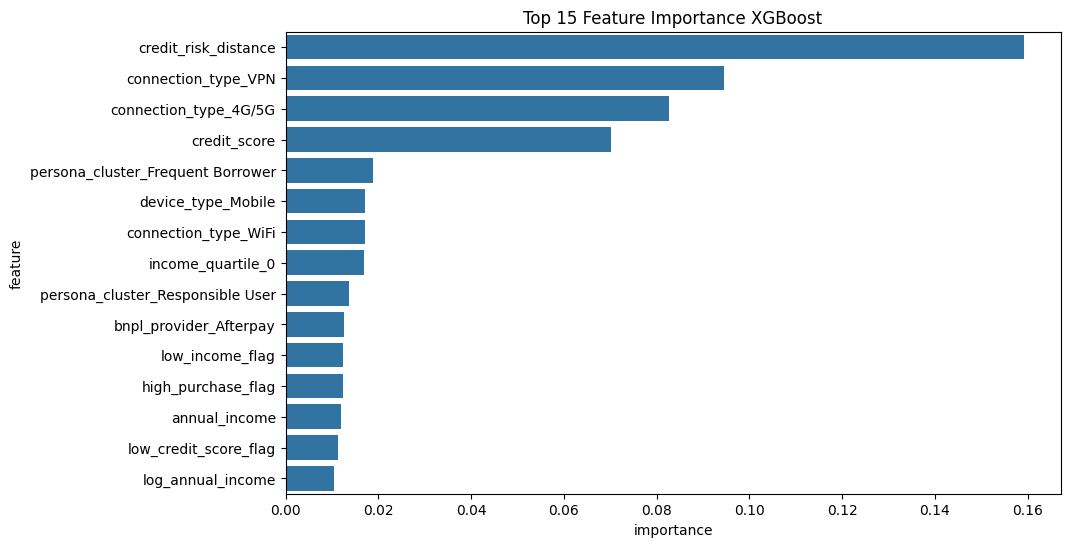

In [ ]:
# feature importance
importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": xgb_model.feature_importances_
}).sort_values("importance", ascending=False)

display(importance_df.head(20))

plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df.head(15), x="importance", y="feature")
plt.title("Top 15 Feature Importance XGBoost")
plt.show()

In [ ]:
# BNPL risk index
# Buat cluster untuk seluruh data
X_all_base = X_base.copy()

X_all_cluster_processed = cluster_preprocessor.transform(X_all_base)
all_clusters = kmeans.predict(X_all_cluster_processed)

df_model["cluster_kmeans"] = all_clusters
df_model["persona"] = pd.Series(all_clusters, index=df_model.index).map(persona_mapping)

persona_profile = df_model.groupby("persona").agg(
    avg_income=("annual_income", "mean"),
    avg_credit_score=("credit_risk_distance", "mean"),
    avg_purchase=("purchase_amount", "mean"),
    default_rate=("default_binary", "mean"),
    total_user=("default_binary", "count")
).reset_index()

# ubah default rate ke persen
persona_profile["default_rate_percent"] = (persona_profile["default_rate"] * 100).round(2)

# fungsi kategori berdasarkan ranking antar persona
def rank_category(series, labels):
    rank = series.rank(method="first")
    return pd.qcut(
        rank,
        q=len(labels),
        labels=labels
    )

persona_profile["income_category"] = rank_category(
    persona_profile["avg_income"],
    ["Rendah", "Sedang", "Tinggi", "Sangat Tinggi"]
)

persona_profile["credit_score_category"] = rank_category(
    persona_profile["avg_credit_score"],
    ["Rendah", "Sedang", "Tinggi", "Sangat Tinggi"]
)

persona_profile["purchase_category_level"] = rank_category(
    persona_profile["avg_purchase"],
    ["Rendah", "Sedang", "Tinggi", "Sangat Tinggi"]
)

# urutan persona agar rapi
persona_order = [
    "Responsible User",
    "Promo Hunter",
    "Frequent Borrower",
    "High Risk Borrower"
]

persona_profile["persona"] = pd.Categorical(
    persona_profile["persona"],
    categories=persona_order,
    ordered=True
)

persona_profile = persona_profile.sort_values("persona")

# tabel ringkas untuk laporan
persona_report_table = persona_profile[[
    "persona",
    "income_category",
    "credit_score_category",
    "purchase_category_level",
    "default_rate_percent",
    "total_user"
]]

persona_report_table.columns = [
    "Persona",
    "Income",
    "Credit Score",
    "Purchase",
    "Default Rate (%)",
    "Jumlah User"
]

display(persona_report_table)

X_all = X_all_base.copy()
X_all["persona_cluster"] = df_model["persona"]

X_all_processed = model_preprocessor.transform(X_all)

df_model["risk_probability"] = xgb_model.predict_proba(X_all_processed)[:, 1]
df_model["bnpl_risk_index"] = (df_model["risk_probability"] * 100).round(2)
df_model["predicted_default"] = (df_model["risk_probability"] >= best_threshold).astype(int)

q1 = df_model["bnpl_risk_index"].quantile(0.25)
q2 = df_model["bnpl_risk_index"].quantile(0.5)
q3 = df_model["bnpl_risk_index"].quantile(0.75)
print(q1, q2, q3)

def risk_level(bnpl_risk_index):
    if bnpl_risk_index <= q1:
        return "Low"
    elif bnpl_risk_index <= q2:
        return "Medium"
    elif bnpl_risk_index <= q3:
        return "High"
    else:
        return "Critical"

df_model["risk_level_final"] = df_model["bnpl_risk_index"].apply(risk_level)

print(" \n")

display(df_model[[
    "persona",
    "repayment_status",
    "default_binary",
    "risk_probability",
    "bnpl_risk_index",
    "risk_level_final",
    "predicted_default"
]].head())

,Persona,Income,Credit Score,Purchase,Default Rate (%),Jumlah User
3,Responsible User,Sangat Tinggi,Rendah,Sedang,12.20,15407
2,Promo Hunter,Sedang,Sedang,Sangat Tinggi,23.14,11737
0,Frequent Borrower,Rendah,Tinggi,Rendah,26.10,9345
1,High Risk Borrower,Tinggi,Sangat Tinggi,Tinggi,33.80,13511


26.139999389648438 52.349998474121094 59.619998931884766
 



,persona,repayment_status,default_binary,risk_probability,bnpl_risk_index,risk_level_final,predicted_default
0,Frequent Borrower,Paid On Time,0,0.567818,56.779999,High,1
1,High Risk Borrower,Paid On Time,0,0.534356,53.439999,High,1
2,Promo Hunter,Paid On Time,0,0.269090,26.910000,Medium,0
3,High Risk Borrower,Paid On Time,0,0.546464,54.650002,High,1
4,Promo Hunter,Defaulted,1,0.623659,62.369999,Critical,1


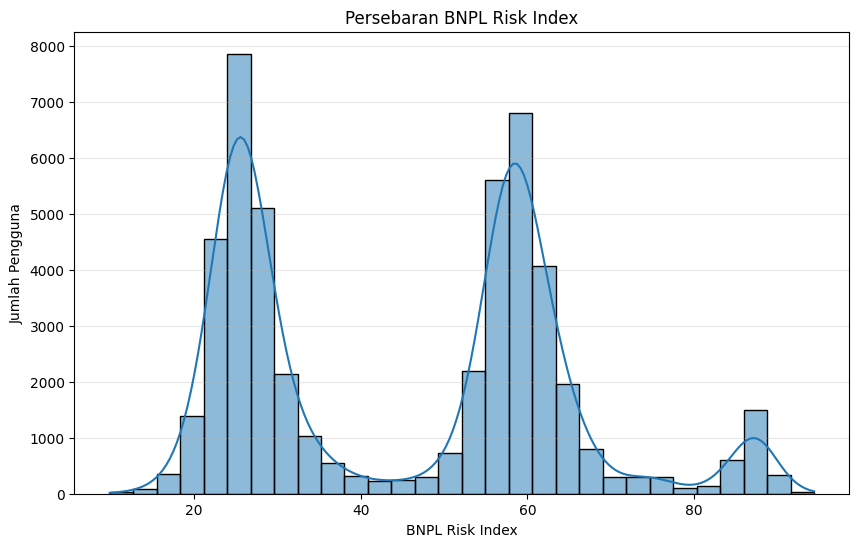

In [ ]:
# distribusi risk index
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_model,
    x="bnpl_risk_index",
    bins=30,
    kde=True
)

plt.title("Persebaran BNPL Risk Index")
plt.xlabel("BNPL Risk Index")
plt.ylabel("Jumlah Pengguna")
plt.grid(axis="y", alpha=0.3)
plt.show()

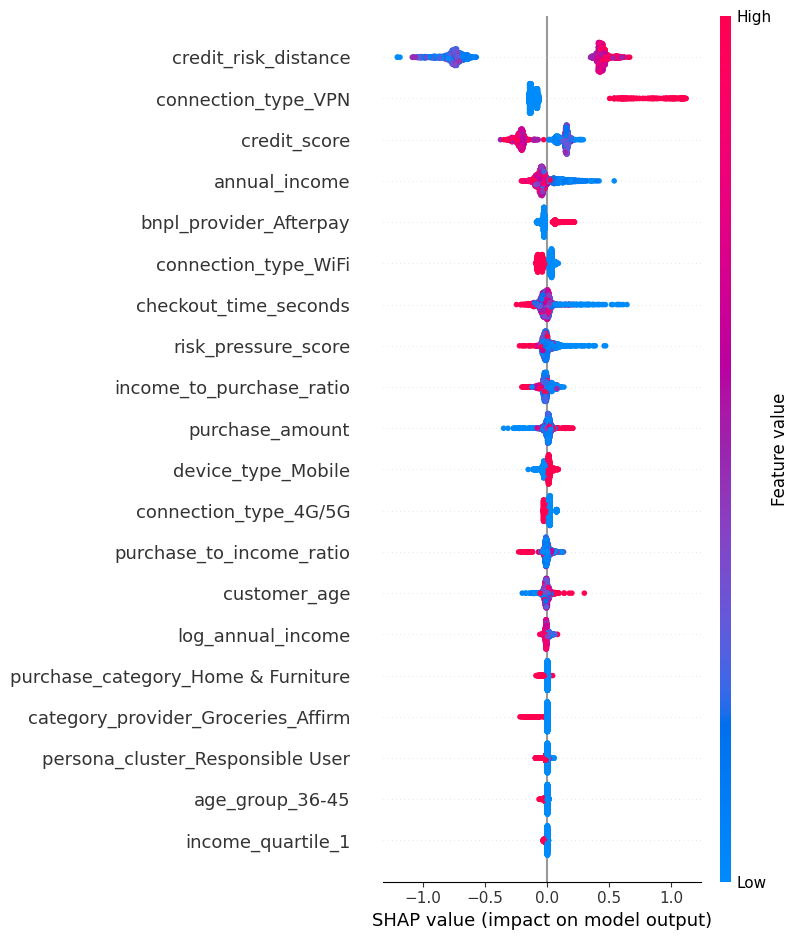

In [ ]:
# SHAP Analysis
# Ambil sample supaya SHAP tidak terlalu berat
sample_size = min(2000, X_test_processed.shape[0])

X_shap = X_test_processed[:sample_size]

explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_shap)

shap.summary_plot(
    shap_values,
    X_shap,
    feature_names=feature_names
)

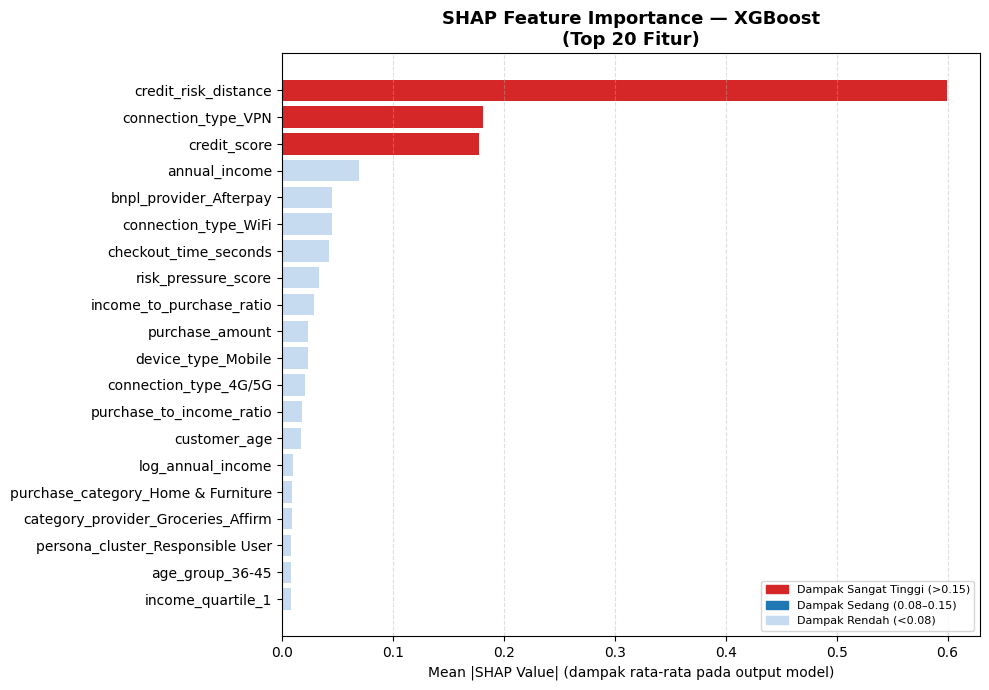

In [ ]:
import matplotlib.patches as mpatches

# Ambil sample agar SHAP tidak terlalu berat
sample_size = min(2000, X_test_processed.shape[0])
X_shap = X_test_processed[:sample_size]

# Buat SHAP explainer
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_shap)

# Jika output SHAP berbentuk list, ambil kelas positif
if isinstance(shap_values, list):
    shap_array = shap_values[1] if len(shap_values) > 1 else shap_values[0]
else:
    shap_array = shap_values

# Hitung rata-rata absolute SHAP value
mean_abs_shap = np.mean(np.abs(shap_array), axis=0)

# Buat dataframe SHAP importance
shap_importance_df = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_abs_shap
}).sort_values("mean_abs_shap", ascending=False)

# Ambil top 20 fitur
top_n = 20
top_features = shap_importance_df.head(top_n).copy()

# Balik urutan agar fitur paling penting ada di atas
top_features = top_features.iloc[::-1]

# Klasifikasi dampak berdasarkan nilai SHAP
def classify_impact(value):
    if value > 0.15:
        return "Dampak Sangat Tinggi (>0.15)"
    elif value > 0.08:
        return "Dampak Sedang (0.08–0.15)"
    else:
        return "Dampak Rendah (<0.08)"

top_features["impact_category"] = top_features["mean_abs_shap"].apply(classify_impact)

# Warna kategori dampak
color_map = {
    "Dampak Sangat Tinggi (>0.15)": "#d62728",
    "Dampak Sedang (0.08–0.15)": "#1f77b4",
    "Dampak Rendah (<0.08)": "#c6dbef"
}

bar_colors = top_features["impact_category"].map(color_map)

# Plot
plt.figure(figsize=(10, 7))

plt.barh(
    top_features["feature"],
    top_features["mean_abs_shap"],
    color=bar_colors
)

plt.title(
    "SHAP Feature Importance — XGBoost\n(Top 20 Fitur)",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel("Mean |SHAP Value| (dampak rata-rata pada output model)")
plt.ylabel("")
plt.grid(axis="x", linestyle="--", alpha=0.4)

# Legend
legend_handles = [
    mpatches.Patch(
        color=color_map["Dampak Sangat Tinggi (>0.15)"],
        label="Dampak Sangat Tinggi (>0.15)"
    ),
    mpatches.Patch(
        color=color_map["Dampak Sedang (0.08–0.15)"],
        label="Dampak Sedang (0.08–0.15)"
    ),
    mpatches.Patch(
        color=color_map["Dampak Rendah (<0.08)"],
        label="Dampak Rendah (<0.08)"
    )
]

plt.legend(
    handles=legend_handles,
    loc="lower right",
    fontsize=8,
    frameon=True
)

plt.tight_layout()

# Simpan gambar untuk laporan
plt.savefig("shap_feature_importance_top20.png", dpi=300, bbox_inches="tight")

plt.show()

In [ ]:
# faktor risiko per user
def get_top_risk_factors_from_test(test_index, top_n=5):
    user_data = X_test_processed[test_index:test_index+1]
    shap_user = explainer.shap_values(user_data)[0]

    factor_table = pd.DataFrame({
        "feature": feature_names,
        "shap_value": shap_user
    })

    factor_table["impact_abs"] = factor_table["shap_value"].abs()

    return factor_table.sort_values("impact_abs", ascending=False).head(top_n)

top_factors = get_top_risk_factors_from_test(0, top_n=5)
display(top_factors)

,feature,shap_value,impact_abs
15,credit_risk_distance,-0.980828,0.980828
34,connection_type_VPN,0.622177,0.622177
2,credit_score,-0.270735,0.270735
4,checkout_time_seconds,0.212827,0.212827
1,annual_income,-0.187445,0.187445


In [ ]:
# export hasil
final_result = df_model[[
    "persona",
    "repayment_status",
    "default_binary",
    "risk_probability",
    "bnpl_risk_index",
    "risk_level_final",
    "predicted_default"
]]

final_result.to_csv("final_bnpl_risk_index_improved.csv", index=False)

display(final_result.head())

print("File berhasil dibuat: final_bnpl_risk_index_improved.csv")

,persona,repayment_status,default_binary,risk_probability,bnpl_risk_index,risk_level_final,predicted_default
0,Frequent Borrower,Paid On Time,0,0.567818,56.779999,High,1
1,High Risk Borrower,Paid On Time,0,0.534356,53.439999,High,1
2,Promo Hunter,Paid On Time,0,0.269090,26.910000,Medium,0
3,High Risk Borrower,Paid On Time,0,0.546464,54.650002,High,1
4,Promo Hunter,Defaulted,1,0.623659,62.369999,Critical,1


File berhasil dibuat: final_bnpl_risk_index_improved.csv
